# Figure S3a–b — Inheritance of batch correction

Source: `time_batch/show_batch.ipynb`. Use saved UMAP coordinates for the original NKT data and three input configurations.
Preserve the source field priority: read X_umap_scGAN if scGAN_clusters is present;
otherwise read X_umap_LassoARE if LassoARE_clusters is present, or X_umap for the remaining case.
Missing coordinates raise an error instead of triggering embedding recomputation or substitution.

**Paths:** The first code cell discovers the data root and prints every input path. If needed, edit `DATA_ROOT` or individual entries in `DATA_FILES` there, then rerun from that cell. Bundled tables and outputs always use this supplementary folder. See `README.md` for details.


In [1]:
FIGURE = 'figS3'

from pathlib import Path

# Leave both settings as None to discover this folder and the data automatically.
# DATA_ROOT may be an absolute path or a path relative to this notebook folder.
SUPP_DIR = None  # Set only if the kernel starts outside the repository/workspace.
DATA_ROOT = None  # Explicit setting takes priority over LASSOARE_DATA_ROOT.

# Relative input paths use DATA_ROOT; individual absolute paths are also supported.
DATA_FILES = {
    'Original': 'NKTCL-NK-10.22.h5ad',
    'PARE_raw': 'time_batch/output_batch/reclustered_adata_test_no_harmony_no_pca.h5ad',
    'PARE_PCA': 'time_batch/output_batch/reclustered_adata_test_no_harmony_pca.h5ad',
    'PARE_PCA_Harmony': 'time_batch/output_batch/reclustered_adata_test_harmony_pca.h5ad',
}

import os
import runpy

# An explicit folder or VS Code's notebook location takes priority over kernel cwd.
_folder = SUPP_DIR if SUPP_DIR is not None else os.environ.get('LASSOARE_SUPPLEMENTARY_DIR')
if _folder is not None:
    _candidates = [Path(_folder).expanduser().resolve()]
else:
    _anchors = []
    if globals().get('__vsc_ipynb_file__'):
        _anchors.append(Path(__vsc_ipynb_file__).expanduser().resolve().parent)
    _anchors.append(Path.cwd())
    _candidates = []
    for _anchor in _anchors:
        for _base in (_anchor, *_anchor.parents):
            _candidates.extend([
                _base, _base / 'supplementary', _base / 'figures_res/supplementary',
                _base / 'Lasso-ARE/figures_res/supplementary',
                _base / 'git_version/Lasso-ARE/figures_res/supplementary',
            ])
SUPP_DIR = next((_p.resolve() for _p in _candidates
                 if all((_p / _name).is_file() for _name in
                        ('supplementary_paths.py', 'supplementary_utils.py', 'inputs/manifest.json'))), None)
if SUPP_DIR is None:
    raise FileNotFoundError(
        f'Cannot locate the supplementary notebook folder from {Path.cwd()}. '
        'Set SUPP_DIR in this cell to the folder containing this notebook, '
        'supplementary_paths.py, supplementary_utils.py and inputs/.'
    )

# Load this copy directly, even if another supplementary folder was used by the kernel.
_paths = runpy.run_path(str(SUPP_DIR / 'supplementary_paths.py'))
_helpers = runpy.run_path(str(SUPP_DIR / 'supplementary_utils.py'))
for _name in ('require_file', 'read_metadata', 'read_expression', 'selection_mask',
              'set_selection', 'save_figure', 'plot_embedding'):
    globals()[_name] = _helpers[_name]
REPO_ROOT = _paths['repository_root'](SUPP_DIR)
DATA_ROOT, DATA_PATHS = _paths['resolve_data_paths'](SUPP_DIR, DATA_FILES, DATA_ROOT)
INPUT_DIR = SUPP_DIR / 'inputs'
OUTPUT_DIR = SUPP_DIR / 'output' / FIGURE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'DejaVu Sans'})
_paths['report_paths'](SUPP_DIR, DATA_ROOT, DATA_PATHS, OUTPUT_DIR)


Notebook folder: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary
Bundled inputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/inputs
Data root: /home/zzj/lare
  OK Original: /home/zzj/lare/NKTCL-NK-10.22.h5ad
  OK PARE_raw: /home/zzj/lare/time_batch/output_batch/reclustered_adata_test_no_harmony_no_pca.h5ad
  OK PARE_PCA: /home/zzj/lare/time_batch/output_batch/reclustered_adata_test_no_harmony_pca.h5ad
  OK PARE_PCA_Harmony: /home/zzj/lare/time_batch/output_batch/reclustered_adata_test_harmony_pca.h5ad
Outputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/output/figS3


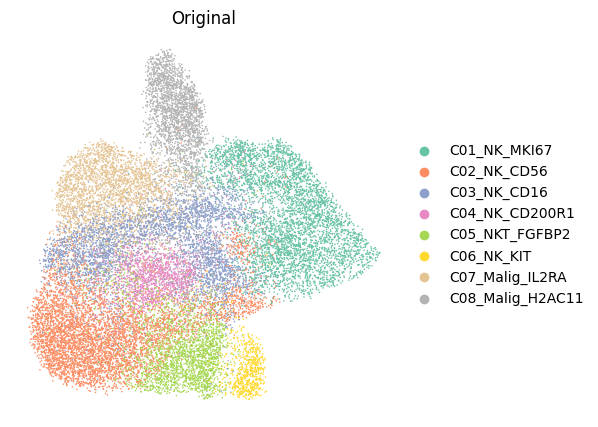

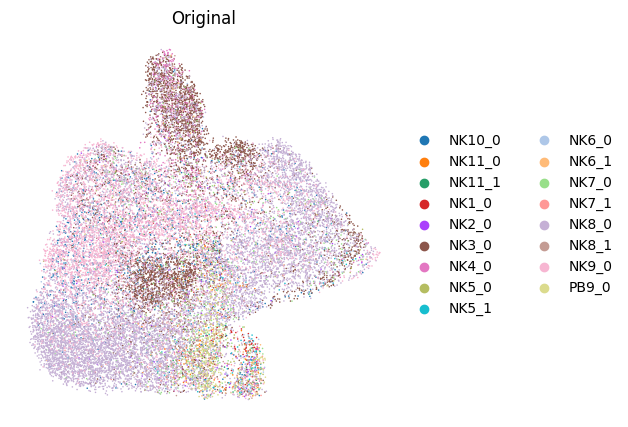

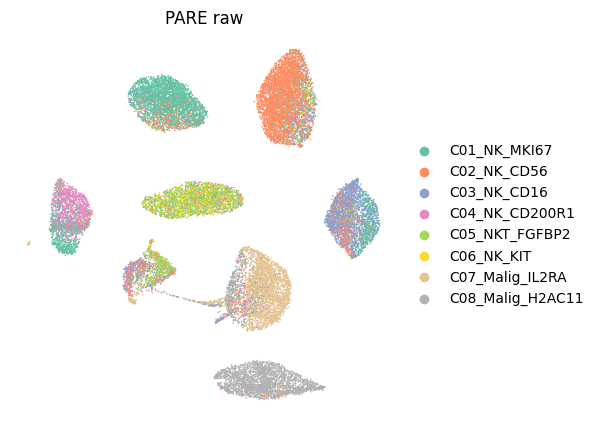

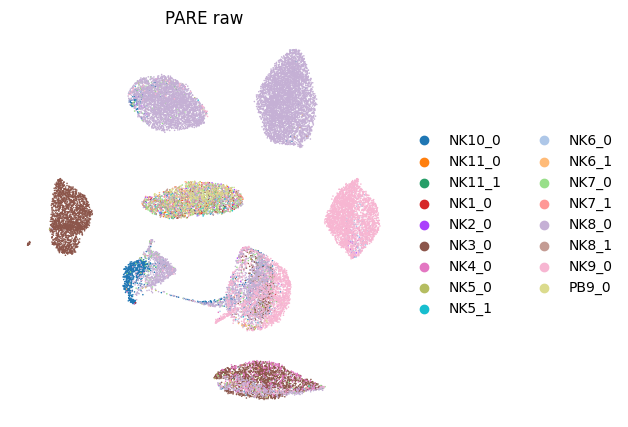

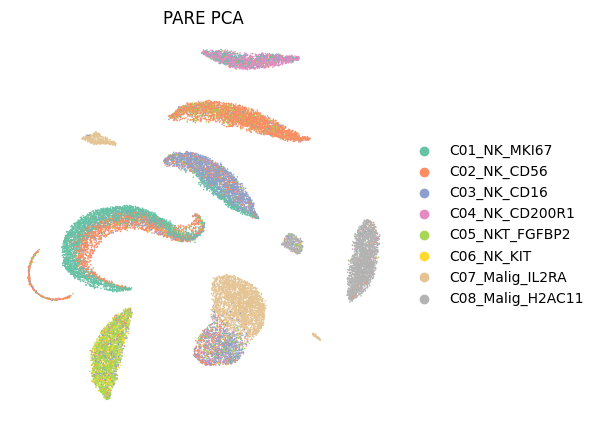

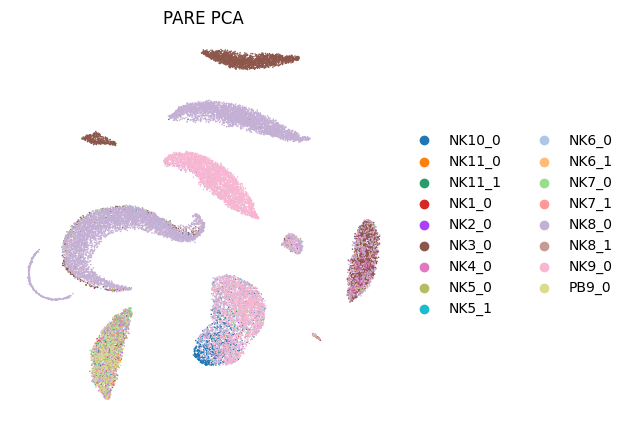

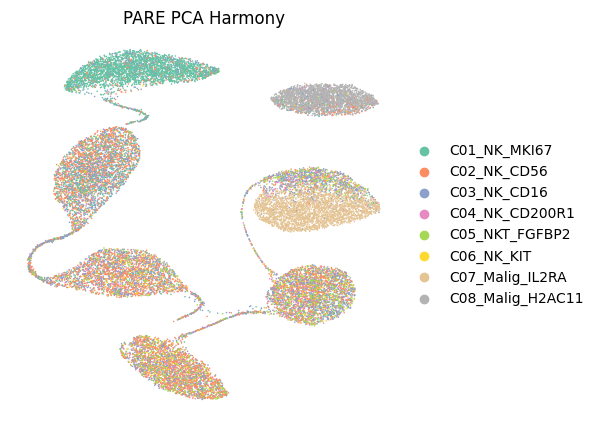

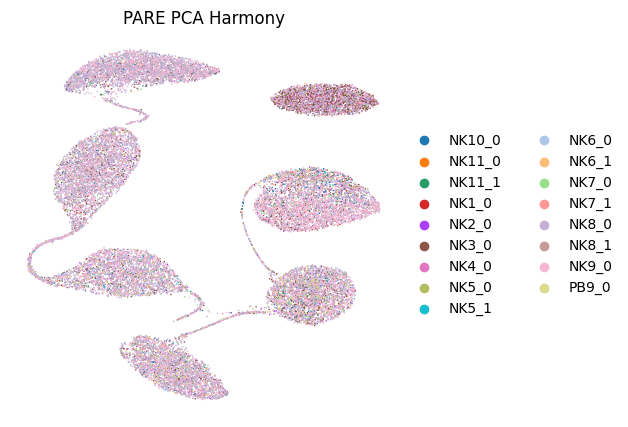

In [2]:
import h5py
SOURCES = {
    'Original': DATA_PATHS['Original'],
    'PARE_raw': DATA_PATHS['PARE_raw'],
    'PARE_PCA': DATA_PATHS['PARE_PCA'],
    'PARE_PCA_Harmony': DATA_PATHS['PARE_PCA_Harmony'],
}
for name, path in SOURCES.items():
    with h5py.File(require_file(path), 'r') as f:
        if name == 'Original':
            basis = 'X_umap'
        elif 'scGAN_clusters' in f['obs']:
            basis = 'X_umap_scGAN'
        elif 'LassoARE_clusters' in f['obs']:
            basis = 'X_umap_LassoARE'
        else:
            basis = 'X_umap'
    adata = read_metadata(path, obsm_keys=[basis])
    for panel, color in [('a', 'anno-NK'), ('b', 'batch')]:
        ax = plot_embedding(adata, color, basis=basis, title=name.replace('_', ' '), size=5)
        save_figure(ax.figure, OUTPUT_DIR, f'figS3{panel}_{name}')
    del adata